# 🏦 Loan Default Prediction using Naïve Bayes



## 🔁 Workflow

```
Load Data → EDA → Preprocessing → Train/Test Split →
Train Model → Evaluate → Visualize Results
```

##  Step 1: Import Libraries

In [50]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



##  Step 2: Load the Dataset

In [51]:
df = pd.read_csv('loan_data (1).csv')
# df.shape
df.isnull().sum()
df.dropna(inplace = True)


##  Step 3: Exploratory Data Analysis (EDA)

<Axes: xlabel='loan_status', ylabel='count'>

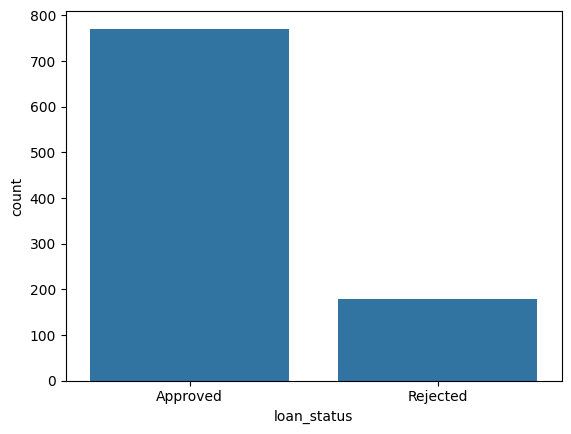

In [52]:
# Basic info
df.info
# Statistical summary
df.describe()
# Missing values
df.isnull().sum()
# Target variable distribution
df['loan_status'].value_counts()

# Correlation heatmap (numeric columns only)
sns.countplot(data = df, x ='loan_status')

## 🛠️ Step 4: Data Preprocessing

> **Why preprocessing?**  
> Naïve Bayes (GaussianNB) works with **numeric values only**.  
> We need to convert categorical columns (text) into numbers using **Label Encoding/ oneHot Encoding**.

In [53]:
df_copy = df.copy()
df_copy = df_copy.drop('applicant_id', axis = 1)

In [54]:
# Identify categorical columns
cat_col = df_copy.select_dtypes(include='object').columns.drop('loan_status')
cat_col

Index(['city', 'education', 'employment_type'], dtype='object')

In [55]:
# one hot encoding
df_copy = df.copy()
df_copy = pd.get_dummies(df_copy,
                         columns = cat_col,
                         dtype = int,
                         drop_first= True)
df_copy.head(2)
df_copy.shape

(950, 19)

In [56]:
df_copy = df_copy.drop('applicant_id', axis = 1)


In [57]:
from sklearn.preprocessing import LabelEncoder

Le = LabelEncoder()
df_copy['loan_status'] = Le.fit_transform(df_copy['loan_status'])
df_copy['loan_status'].head()

,loan_status
0,0
1,1
2,0
3,0
4,0


In [58]:
X = df_copy.drop('loan_status', axis = 1)
y = df_copy['loan_status']


In [59]:
# Define Features (X) and Target (y)

## ✂️ Step 5: Train-Test Split

> We split the data into **80% training** and **20% testing**.  
> The model **learns from training data** and is **evaluated on test data** it has never seen.

In [60]:
# Train-Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)

In [61]:
# Perform class imbalance
from imblearn.over_sampling import SMOTE
sm = SMOTE(random_state=42)
X_train, y_train = sm.fit_resample(X_train, y_train)
X_train.shape, y_train.shape

((1048, 17), (1048,))

## 🤖 Step 6: Train the Naïve Bayes Model

> **GaussianNB** assumes features follow a **Normal (Gaussian) distribution**.  
> It calculates the **mean** and **variance** of each feature for each class.

In [62]:
# Initialize and Train the model
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()
gnb.fit(X_train, y_train)


GaussianNB()

In [63]:
y_pred = gnb.predict(X_test)
y_pred[:10]

array([0, 0, 1, 0, 0, 1, 1, 0, 1, 1])

In [64]:
compare = pd.DataFrame({
    'Actual' : y_test,
    'Predicted' : y_pred
})
compare.head(10)

,Actual,Predicted
210,0,0
977,0,0
726,0,1
836,1,0
918,0,0
607,0,1
865,0,1
972,0,0
517,1,1
184,0,1


## 📊 Step 7: Model Evaluation

In [65]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score


In [66]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

print(f' The precision score is {precision_score(y_test, y_pred)}')

print(f' The recall score is {recall_score(y_test, y_pred)}')

print(f' The f1 score is {f1_score(y_test, y_pred, average='micro')}')

print(f' The accuracy score is {accuracy_score(y_test, y_pred)}')


 The precision score is 0.22959183673469388
 The recall score is 0.6716417910447762
 The f1 score is 0.44904458598726116
 The accuracy score is 0.44904458598726116


## 🔮 Step 8: Predict for a New Loan Applicant

> Let's simulate a **real-world prediction** for a new applicant who has **not been seen by the model** before.

In [67]:
new_applicant = pd.DataFrame([
    {
        "age": 35,
        "annual_income": 600000,
        "loan_amount": 300000,
        "monthly_emi": 15000,
        "credit_score": 750,
        "existing_loans": 1,
        "city": "Delhi",
        "education": "Graduate",
        "employment_type": "Salaried",
        "has_property": 1
    }
])

# Get the categorical columns used during training
# (cat_col was defined as ['city', 'education', 'employment_type'])
cat_col = ['city', 'education', 'employment_type']

# One-hot encode the new applicant data
new_applicant_encoded = pd.get_dummies(new_applicant, columns=cat_col, dtype=int, drop_first=True)

# Align columns with X_train. This ensures all columns from X_train are present
# and in the correct order, filling missing ones with 0.
missing_cols = set(X_train.columns) - set(new_applicant_encoded.columns)
for c in missing_cols:
    new_applicant_encoded[c] = 0

# Ensure the order of columns in new_applicant_encoded matches X_train
new_applicant_processed = new_applicant_encoded[X_train.columns]

prediction = gnb.predict(new_applicant_processed)[0]
probability = gnb.predict_proba(new_applicant_processed)[0]

status = "Rejected" if prediction == 1 else "Approved"

print("Predicted Loan Status:", status)
print("Approved probability:", round(probability[0] * 100, 2), "%")
print("Rejected probability:", round(probability[1] * 100, 2), "%")

Predicted Loan Status: Rejected
Approved probability: 31.07 %
Rejected probability: 68.93 %


# KNN

In [68]:
from sklearn.neighbors import KNeighborsClassifier


### Feature Scaling for KNN

> KNN is sensitive to the scale of the features. We need to standardize the features so that all features contribute equally to the distance calculation.

In [69]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Featured scaled successfully")

Featured scaled successfully


### Train the KNN Model

> We will train a K-Nearest Neighbors classifier on the scaled training data.

In [70]:
# Initialize KNN classifier with n_neighbors (e.g., 5)
neigh = KNeighborsClassifier(n_neighbors=18)

neigh.fit(X_train_scaled, y_train)







KNeighborsClassifier(n_neighbors=18)

### Make Predictions with KNN

In [71]:
y_predict = neigh.predict(X_test_scaled)
y_predict[:10]

array([0, 1, 1, 0, 0, 0, 0, 0, 0, 0])

In [72]:
compare = pd.DataFrame({
    'Actual' : y_test,
    'Predicted' : y_predict
})
compare.head(10)

,Actual,Predicted
210,0,0
977,0,1
726,0,1
836,1,0
918,0,0
607,0,0
865,0,0
972,0,0
517,1,0
184,0,0


### Evaluate the KNN Model

> We will evaluate the KNN model using a classification report and confusion matrix to understand its performance.

In [73]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

print(f' The precision score is {precision_score(y_test, y_predict)}')

print(f' The recall score is {recall_score(y_test, y_predict)}')

print(f' The f1 score is {f1_score(y_test, y_predict, average='micro')}')

print(f' The accuracy score is {accuracy_score(y_test, y_predict)}')


 The precision score is 0.2037037037037037
 The recall score is 0.16417910447761194
 The f1 score is 0.6847133757961783
 The accuracy score is 0.6847133757961783


### Visualize Confusion Matrix for KNN

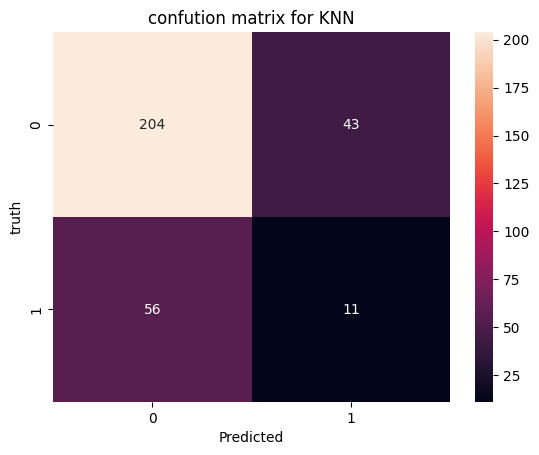

In [74]:
from sklearn.metrics import confusion_matrix
C_knn = confusion_matrix(y_test, y_predict)
sns.heatmap(C_knn, annot=True, fmt='d')
plt.title('confution matrix for KNN')
plt.xlabel('Predicted')
plt.ylabel('truth')
plt.show()

### Elbow Method for Optimal K (K-Means Clustering)



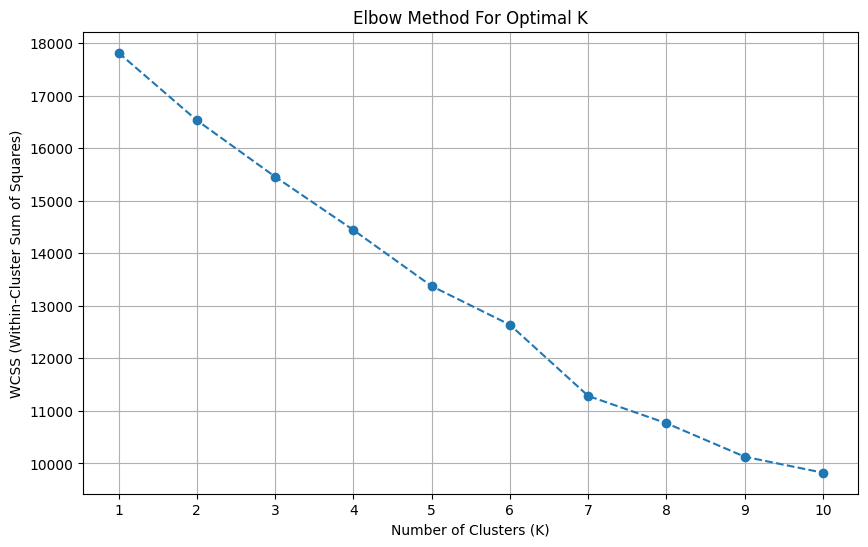

In [75]:
from sklearn.cluster import KMeans
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_train_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [76]:
import pickle

# Save the KNN model
with open('knn_model.pkl', 'wb') as file:
    pickle.dump(neigh, file)
print('KNN model saved as knn_model.pkl')

# Save the StandardScaler
with open('scaler.pkl', 'wb') as file:
    pickle.dump(scaler, file)
print('StandardScaler saved as scaler.pkl')

KNN model saved as knn_model.pkl
StandardScaler saved as scaler.pkl


In [77]:
import pickle

# Save the Naive Bayes model
with open('naive_bayes_model.pkl', 'wb') as file:
    pickle.dump(gnb, file)
print('Naive Bayes model saved as naive_bayes_model.pkl')

Naive Bayes model saved as naive_bayes_model.pkl
